<a href="https://colab.research.google.com/github/daviminati/Trabalho_Des.Aplicacoes_Computacionais/blob/main/Entrega_Otimizadores.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 13. Divisão dos Dados (Treino e Teste) e Validação Cruzada
Nesta etapa, dividimos o conjunto de variáveis de interesse em treino (80%) e teste (20%), avaliando diferentes algoritmos de regressão para prever `SalePrice` (`RMSE`, `MAE`, `R²` e validação cruzada de 5 *folds*). Para os modelos lineares/regularizados, utilizamos os dados padronizados (`StandardScaler`) ajustados exclusivamente no conjunto de treino para evitar *data leakage*.

=== RESULTADOS DOS MODELOS ===


,Modelo,RMSE ($),MAE ($),R2 Teste,R2 CV Média,R2 CV Desvio
4,Gradient Boosting,28049.39,18686.16,0.8974,0.7908,0.1012
3,Random Forest,29191.53,19102.90,0.8889,0.7963,0.0865
0,Regressão Linear,39710.99,25319.86,0.7944,0.7462,0.0701
2,Lasso (alpha=100),39739.36,25316.16,0.7941,0.7462,0.0694
1,Ridge (alpha=10),39757.41,25304.30,0.7939,0.7467,0.0688


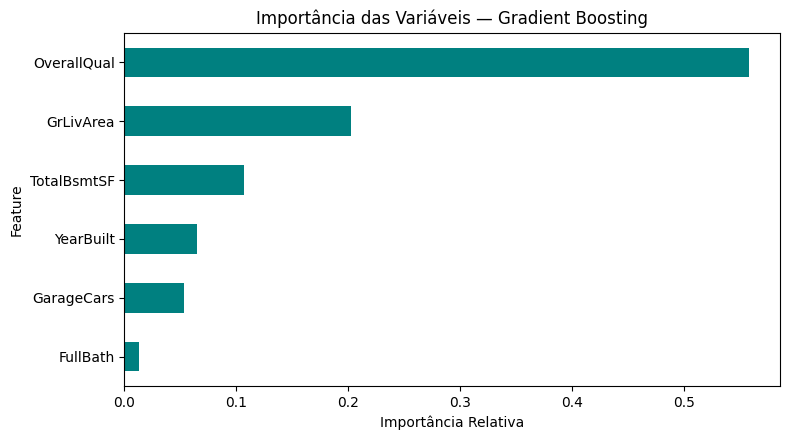


Melhores hiperparâmetros: {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 250, 'subsample': 1.0}
Modelo Final (Teste) -> RMSE: $27,932.58 | MAE: $18,370.25 | R²: 0.8983


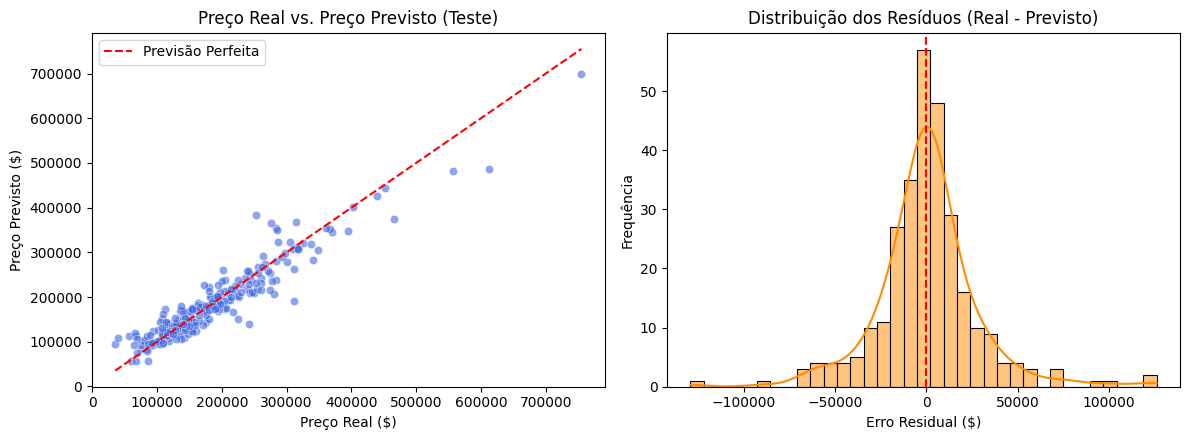


Arquivo 'previsoes_teste.csv' salvo com sucesso!


,Id,SalePrice
0,1461,125403.86
1,1462,149743.03
2,1463,162358.41
3,1464,181965.90
4,1465,209360.33


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

url_train = 'https://raw.githubusercontent.com/daviminati/house-prices-data/main/train.csv'
url_test = 'https://raw.githubusercontent.com/daviminati/house-prices-data/main/test.csv'

features = ['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'FullBath', 'YearBuilt']
target = 'SalePrice'

# Carga e tratamento inicial direto do GitHub (mantendo a mesma lógica do Entregável 1)
df_raw = pd.read_csv(url_train)
num_cols = df_raw.select_dtypes(include=[np.number]).columns
cat_cols = df_raw.select_dtypes(include=['object']).columns

df_raw[num_cols] = df_raw[num_cols].fillna(df_raw[num_cols].median())
df_raw[cat_cols] = df_raw[cat_cols].fillna('None')

df_ml = df_raw[features + [target]].copy()

X = df_ml[features]
y = df_ml[target]

# Divisão treino / teste (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Padronização apenas para modelos lineares/regularizados (fit apenas no treino)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Treinamento e avaliação comparativa dos modelos
modelos = {
    'Regressão Linear': (LinearRegression(), X_train_scaled, X_test_scaled),
    'Ridge (alpha=10)': (Ridge(alpha=10.0), X_train_scaled, X_test_scaled),
    'Lasso (alpha=100)': (Lasso(alpha=100.0, max_iter=10000), X_train_scaled, X_test_scaled),
    'Random Forest': (RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1), X_train, X_test),
    'Gradient Boosting': (GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, random_state=42), X_train, X_test)
}

resultados = []
for nome, (modelo, X_tr, X_te) in modelos.items():
    modelo.fit(X_tr, y_train)
    y_pred = modelo.predict(X_te)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    cv_r2 = cross_val_score(modelo, X_tr, y_train, cv=5, scoring='r2')

    resultados.append({
        'Modelo': nome,
        'RMSE ($)': round(rmse, 2),
        'MAE ($)': round(mae, 2),
        'R2 Teste': round(r2, 4),
        'R2 CV Média': round(cv_r2.mean(), 4),
        'R2 CV Desvio': round(cv_r2.std(), 4)
    })

df_resultados = pd.DataFrame(resultados).sort_values(by='R2 Teste', ascending=False)
print("=== RESULTADOS DOS MODELOS ===")
display(df_resultados)

# Importância das variáveis no Gradient Boosting
gb_base = modelos['Gradient Boosting'][0]
importancias = pd.Series(gb_base.feature_importances_, index=features).sort_values(ascending=True)

plt.figure(figsize=(8, 4.5))
importancias.plot(kind='barh', color='teal')
plt.title('Importância das Variáveis — Gradient Boosting')
plt.xlabel('Importância Relativa')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# Otimização de hiperparâmetros com GridSearchCV
param_grid = {
    'n_estimators': [150, 250],
    'learning_rate': [0.03, 0.05, 0.08],
    'max_depth': [3, 4],
    'subsample': [0.8, 1.0]
}

grid_search = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)
modelo_final = grid_search.best_estimator_

y_pred_final = modelo_final.predict(X_test)
rmse_final = np.sqrt(mean_squared_error(y_test, y_pred_final))
mae_final = mean_absolute_error(y_test, y_pred_final)
r2_final = r2_score(y_test, y_pred_final)

print("\nMelhores hiperparâmetros:", grid_search.best_params_)
print(f"Modelo Final (Teste) -> RMSE: ${rmse_final:,.2f} | MAE: ${mae_final:,.2f} | R²: {r2_final:.4f}")

# Diagnóstico de resíduos
residuos = y_test - y_pred_final
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.scatterplot(x=y_test, y=y_pred_final, alpha=0.6, color='royalblue', ax=axes[0])
min_val = min(y_test.min(), y_pred_final.min())
max_val = max(y_test.max(), y_pred_final.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=1.5, label='Previsão Perfeita')
axes[0].set_title('Preço Real vs. Preço Previsto (Teste)')
axes[0].set_xlabel('Preço Real ($)')
axes[0].set_ylabel('Preço Previsto ($)')
axes[0].legend()

sns.histplot(residuos, kde=True, color='darkorange', ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title('Distribuição dos Resíduos (Real - Previsto)')
axes[1].set_xlabel('Erro Residual ($)')
axes[1].set_ylabel('Frequência')

plt.tight_layout()
plt.show()

# Previsões no test.csv
df_test_raw = pd.read_csv(url_test)
medianas_feat = df_raw[features].median()
X_sub = df_test_raw[features].fillna(medianas_feat)
preds_sub = modelo_final.predict(X_sub)

df_submissao = pd.DataFrame({
    'Id': df_test_raw['Id'],
    'SalePrice': np.round(preds_sub, 2)
})
df_submissao.to_csv('previsoes_teste.csv', index=False)
print("\nArquivo 'previsoes_teste.csv' salvo com sucesso!")
display(df_submissao.head())

## 14. Importância das Features
Analisamos quais variáveis de entrada têm maior peso na redução do erro nos modelos baseados em árvores (`Gradient Boosting`), identificando os principais direcionadores de preço do conjunto de dados.

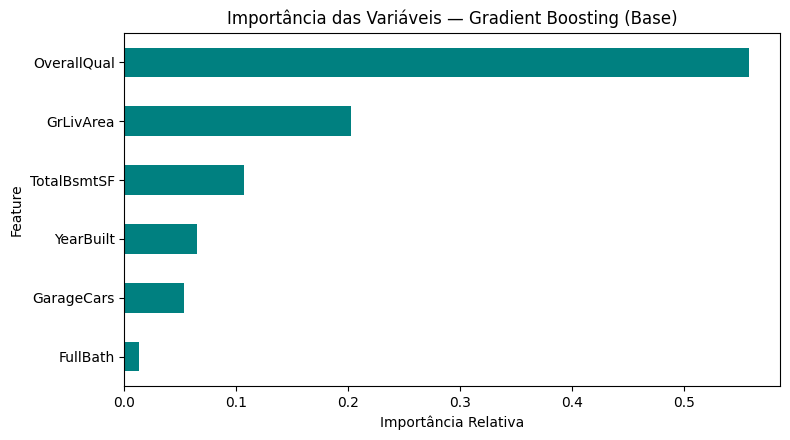

In [14]:
melhor_modelo_base = modelos['Gradient Boosting'][0]

importancias = pd.Series(
    melhor_modelo_base.feature_importances_,
    index=features
).sort_values(ascending=True)

plt.figure(figsize=(8, 4.5))
importancias.plot(kind='barh', color='teal')
plt.title('Importância das Variáveis — Gradient Boosting (Base)')
plt.xlabel('Importância Relativa')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## 15. Otimização de Hiperparâmetros (`GridSearchCV`)
Buscamos melhorar a capacidade de generalização do `GradientBoostingRegressor` ajustando hiperparâmetros como profundidade das árvores (`max_depth`), taxa de aprendizado (`learning_rate`), número de estimadores (`n_estimators`) e fração de amostras (`subsample`) via validação cruzada.

In [15]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [150, 250],
    'learning_rate': [0.03, 0.05, 0.08],
    'max_depth': [3, 4],
    'subsample': [0.8, 1.0]
}

gb_base = GradientBoostingRegressor(random_state=42)

grid_search = GridSearchCV(
    estimator=gb_base,
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
modelo_final = grid_search.best_estimator_

y_pred_final = modelo_final.predict(X_test)
rmse_final = np.sqrt(mean_squared_error(y_test, y_pred_final))
mae_final = mean_absolute_error(y_test, y_pred_final)
r2_final = r2_score(y_test, y_pred_final)

print("Melhores hiperparâmetros encontrados:")
print(grid_search.best_params_)
print(f"\nDesempenho no conjunto de teste:")
print(f"RMSE: ${rmse_final:,.2f}")
print(f"MAE:  ${mae_final:,.2f}")
print(f"R²:   {r2_final:.4f}")

Melhores hiperparâmetros encontrados:
{'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 250, 'subsample': 1.0}

Desempenho no conjunto de teste:
RMSE: $27,932.58
MAE:  $18,370.25
R²:   0.8983


## 16. Diagnóstico de Resíduos (Valores Reais vs. Previstos)
Verificamos a aderência das previsões aos valores reais no conjunto de teste e a distribuição dos resíduos (`y_test - y_pred_final`) para checar possíveis vieses ou imóveis de alto padrão com maior erro absoluto.

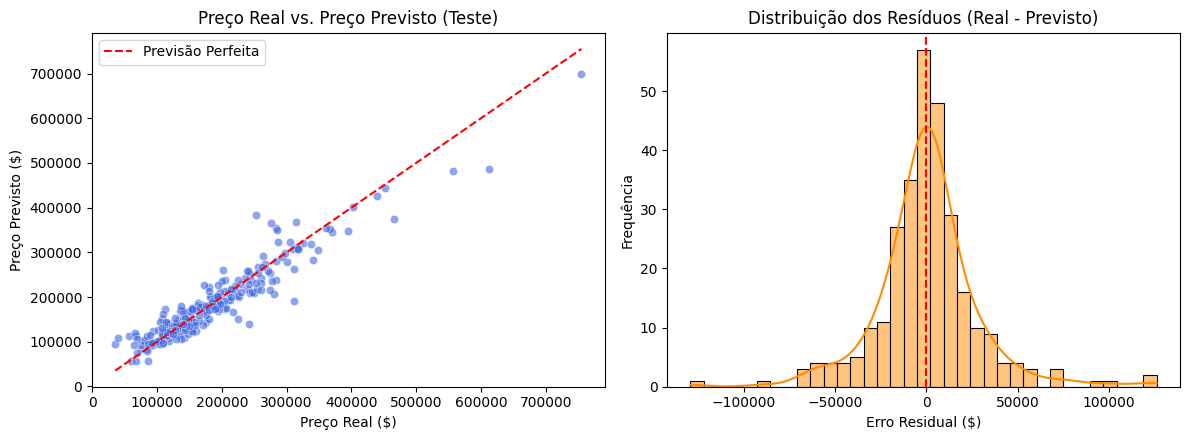

In [16]:
residuos = y_test - y_pred_final

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Real vs. Previsto
sns.scatterplot(x=y_test, y=y_pred_final, alpha=0.6, color='royalblue', ax=axes[0])
min_val = min(y_test.min(), y_pred_final.min())
max_val = max(y_test.max(), y_pred_final.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=1.5, label='Previsão Perfeita')
axes[0].set_title('Preço Real vs. Preço Previsto (Teste)')
axes[0].set_xlabel('Preço Real ($)')
axes[0].set_ylabel('Preço Previsto ($)')
axes[0].legend()

# Distribuição dos resíduos
sns.histplot(residuos, kde=True, color='darkorange', ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title('Distribuição dos Resíduos (Real - Previsto)')
axes[1].set_xlabel('Erro Residual ($)')
axes[1].set_ylabel('Frequência')

plt.tight_layout()
plt.show()

## 17. Preparação de `test.csv` e Exportação das Previsões Finais
Aplicamos o mesmo tratamento de valores faltantes no `test.csv` (usando a mediana de `train.csv` para variáveis numéricas e `'None'` para categóricas, evitando *data leakage*) e exportamos o arquivo `previsoes_teste.csv` com `Id` e `SalePrice` previsto.

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler

# Se estiver no Google Drive, descomente as duas linhas abaixo e ajuste o caminho:
# from google.colab import drive
# drive.mount('/content/drive')

df_ml = pd.read_csv('variaveis_interesse.csv')

features = [
    'OverallQual',
    'GrLivArea',
    'GarageCars',
    'TotalBsmtSF',
    'FullBath',
    'YearBuilt',
]
target = 'SalePrice'

X = df_ml[features]
y = df_ml[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

modelos = {
    'Regressão Linear': (LinearRegression(), X_train_scaled, X_test_scaled),
    'Ridge (alpha=10)': (Ridge(alpha=10.0), X_train_scaled, X_test_scaled),
    'Lasso (alpha=100)': (
        Lasso(alpha=100.0, max_iter=10000),
        X_train_scaled,
        X_test_scaled,
    ),
    'Random Forest': (
        RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
        X_train,
        X_test,
    ),
    'Gradient Boosting': (
        GradientBoostingRegressor(
            n_estimators=200, learning_rate=0.05, random_state=42
        ),
        X_train,
        X_test,
    ),
}

resultados = []
for nome, (modelo, X_tr, X_te) in modelos.items():
  modelo.fit(X_tr, y_train)
  y_pred = modelo.predict(X_te)

  rmse = np.sqrt(mean_squared_error(y_test, y_pred))
  mae = mean_absolute_error(y_test, y_pred)
  r2 = r2_score(y_test, y_pred)
  cv_r2 = cross_val_score(modelo, X_tr, y_train, cv=5, scoring='r2')

  resultados.append({
      'Modelo': nome,
      'RMSE ($)': round(rmse, 2),
      'MAE ($)': round(mae, 2),
      'R2 Teste': round(r2, 4),
      'R2 CV Média': round(cv_r2.mean(), 4),
      'R2 CV Desvio': round(cv_r2.std(), 4),
  })

df_resultados = pd.DataFrame(resultados).sort_values(
    by='R2 Teste', ascending=False
)
display(df_resultados)

,Modelo,RMSE ($),MAE ($),R2 Teste,R2 CV Média,R2 CV Desvio
4,Gradient Boosting,28049.39,18686.16,0.8974,0.7908,0.1012
3,Random Forest,29191.53,19102.90,0.8889,0.7963,0.0865
0,Regressão Linear,39710.99,25319.86,0.7944,0.7462,0.0701
2,Lasso (alpha=100),39739.36,25316.16,0.7941,0.7462,0.0694
1,Ridge (alpha=10),39757.41,25304.30,0.7939,0.7467,0.0688


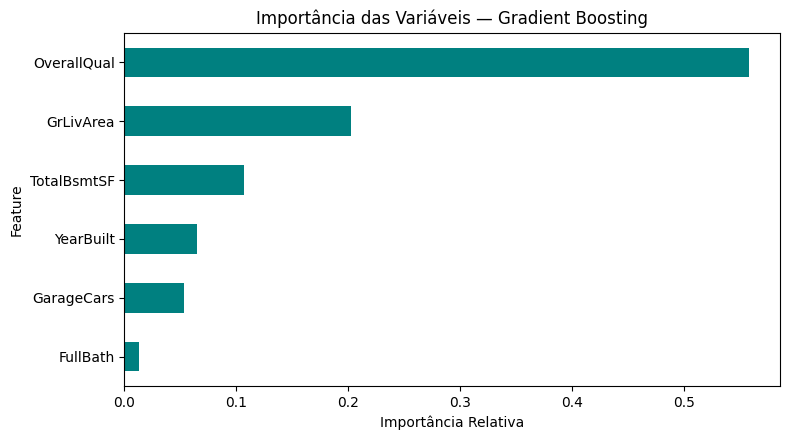

Melhores hiperparâmetros: {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 250, 'subsample': 1.0}
Modelo Final -> RMSE: $27,932.58 | MAE: $18,370.25 | R²: 0.8983


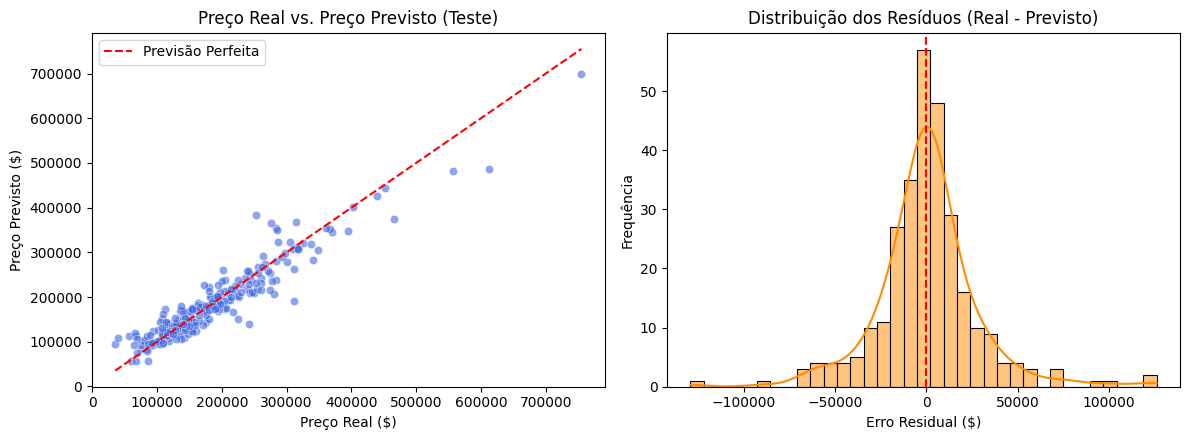

In [18]:
from sklearn.model_selection import GridSearchCV

gb_base = modelos['Gradient Boosting'][0]
importancias = pd.Series(
    gb_base.feature_importances_, index=features
).sort_values(ascending=True)

plt.figure(figsize=(8, 4.5))
importancias.plot(kind='barh', color='teal')
plt.title('Importância das Variáveis — Gradient Boosting')
plt.xlabel('Importância Relativa')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

param_grid = {
    'n_estimators': [150, 250],
    'learning_rate': [0.03, 0.05, 0.08],
    'max_depth': [3, 4],
    'subsample': [0.8, 1.0],
}

grid_search = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)
modelo_final = grid_search.best_estimator_

y_pred_final = modelo_final.predict(X_test)
rmse_final = np.sqrt(mean_squared_error(y_test, y_pred_final))
mae_final = mean_absolute_error(y_test, y_pred_final)
r2_final = r2_score(y_test, y_pred_final)

print('Melhores hiperparâmetros:', grid_search.best_params_)
print(
    f'Modelo Final -> RMSE: ${rmse_final:,.2f} | MAE: ${mae_final:,.2f} | R²:'
    f' {r2_final:.4f}'
)

residuos = y_test - y_pred_final
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.scatterplot(
    x=y_test, y=y_pred_final, alpha=0.6, color='royalblue', ax=axes[0]
)
min_val = min(y_test.min(), y_pred_final.min())
max_val = max(y_test.max(), y_pred_final.max())
axes[0].plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    linewidth=1.5,
    label='Previsão Perfeita',
)
axes[0].set_title('Preço Real vs. Preço Previsto (Teste)')
axes[0].set_xlabel('Preço Real ($)')
axes[0].set_ylabel('Preço Previsto ($)')
axes[0].legend()

sns.histplot(residuos, kde=True, color='darkorange', ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title('Distribuição dos Resíduos (Real - Previsto)')
axes[1].set_xlabel('Erro Residual ($)')
axes[1].set_ylabel('Frequência')

plt.tight_layout()
plt.show()

In [19]:
df_test_raw = pd.read_csv('test.csv')
medianas_feat = X_train[features].median()

X_sub = df_test_raw[features].fillna(medianas_feat)
preds_sub = modelo_final.predict(X_sub)

df_submissao = pd.DataFrame(
    {'Id': df_test_raw['Id'], 'SalePrice': np.round(preds_sub, 2)}
)
df_submissao.to_csv('previsoes_teste.csv', index=False)
print("Ficheiro 'previsoes_teste.csv' guardado com sucesso!")
display(df_submissao.head())

Ficheiro 'previsoes_teste.csv' guardado com sucesso!


,Id,SalePrice
0,1461,125403.86
1,1462,149743.03
2,1463,162358.41
3,1464,181965.90
4,1465,209360.33
